# NETBCI 全部发布身份：纵向结果、数值副本与来源敏感性

可重运行、原生可编辑 Matplotlib 图。仅读取保存结果及 SHA-256 收据；
不加载 EEG 张量、不拟合模型、不改变参数。发布编号不等于已证实独立的生物学参与者。
全编号的 EEG bootstrap 是算术记录；来源敏感性依据全部连续信号或任务窗口跨编号副本，
同时排除每组所有编号，不按结果筛选。此扩展发生于已见十编号结果之后，属于探索性分析。

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import io
import json
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "configs/netbci_cohort_all19_20261010.json").is_file()), None)
assert ROOT is not None, "Run from this repository."
def sha256(path):
    with Path(path).open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()
def read_json(path):
    return json.loads(Path(path).read_text())
def table(path):
    return pd.read_csv(path, sep="\t", dtype={"subject": str, "session": str},
                       keep_default_na=True)

In [2]:
RESULTS = ROOT / 'research_logs/netbci_cohort_all19_20261010/summary_run01'
AUDIT = RESULTS.parent
VALIDATION_RUN = 'notebook_validation_run03'
CONFIG = ROOT / "configs/netbci_cohort_all19_20261010.json"
COMPACT = AUDIT / "numeric_signal_identity_summary_v2.json"
SENSITIVITY = AUDIT / "independence_sensitivity_run01"
receipt = read_json(RESULTS / "summary_receipt.json")
summary = read_json(RESULTS / "cohort_summary.json")
config = read_json(CONFIG)
compact = read_json(COMPACT)
sensitive_receipt = read_json(SENSITIVITY / "sensitivity_receipt.json")
sensitivity = read_json(SENSITIVITY / "sensitivity_summary.json")
LEDGER = Path(compact["full_ledger_file"])
if not LEDGER.is_file():
    LEDGER = AUDIT / LEDGER.name
assert receipt["status"] == "actual_data_summary_completed" and receipt["synthetic"] is False
assert summary["status"] == "actual_audited_published_ID_cohort_exploratory"
assert summary["synthetic"] is False and compact["synthetic"] is False
assert compact["status"] == "compact_verified_pre_model_numeric_identity_summary"
assert sha256(CONFIG) == receipt["config_sha256"] == compact["configuration_sha256"]
assert sha256(LEDGER) == compact["full_ledger_sha256"]
assert sha256(LEDGER) == sensitive_receipt["input_sha256"]["identity_audit"]["sha256"]
assert sha256(RESULTS / "summary_receipt.json") == sensitive_receipt["input_sha256"]["summary_receipt"]["sha256"]
assert sensitive_receipt["status"] == "completed_real_data_sensitivity"
assert sensitive_receipt["synthetic"] is False
assert sensitive_receipt["original_primary_outputs_modified"] is False
assert sensitivity["no_model_refitting"] and sensitivity["not_independent_confirmation"]
assert receipt["bootstrap_unit"] == "whole published identity trajectory"
source_rows = []
for directory, record in [(RESULTS, receipt), (SENSITIVITY, sensitive_receipt)]:
    for name, checksum in record["output_sha256"].items():
        assert sha256(directory / name) == checksum, name
        source_rows.append({"artifact": str((directory / name).relative_to(ROOT)), "SHA256": checksum})
for name, item in receipt["input_sha256"].items():
    path = Path(item["path"])
    if not path.exists() and "/few-shot-mi-eeg/" in item["path"]:
        path = ROOT / item["path"].split("/few-shot-mi-eeg/", 1)[1]
    assert sha256(path) == item["sha256"], name
for path in [CONFIG, COMPACT, LEDGER, RESULTS / "summary_receipt.json",
             SENSITIVITY / "sensitivity_receipt.json"]:
    source_rows.append({"artifact": str(path.relative_to(ROOT)), "SHA256": sha256(path)})
OFFICIAL_MANIFEST = Path(compact["official_manifest_file"]).resolve()
assert sha256(OFFICIAL_MANIFEST) == compact["official_manifest_sha256"]
source_rows.append({"artifact": str(OFFICIAL_MANIFEST.relative_to(ROOT)),
                    "SHA256": sha256(OFFICIAL_MANIFEST)})
SUBJECTS, SESSIONS = config["subjects"], config["session_order"]
assert SUBJECTS == [f"sub-{i}" for i in range(1, 20)]
RETAINED, EXCLUDED = sensitivity["retained_identities"], sensitivity["excluded_identities"]
assert EXCLUDED == compact["cross_subject_affected_identities"]
assert RETAINED == compact["identities_without_detected_cross_subject_exact_signal_copies"]
assert not set(RETAINED) & set(EXCLUDED) and set(RETAINED + EXCLUDED) == set(SUBJECTS)
assert summary["published_identities"] == len(SUBJECTS)
assert compact["summary"]["continuous_runs"] == len(SUBJECTS) * len(SESSIONS) * 6
assert compact["summary"]["official_manifest_matches"] == compact["summary"]["continuous_runs"]
old_config = read_json(ROOT / "configs/netbci_cohort_full_windows_20261010.json")
SCIENCE_KEYS = ["seed", "threads", "session_order", "expected_runs", "source_train_runs",
    "source_query_runs", "later_query_runs", "expected_sfreq_hz", "reference", "roi_channels",
    "decoder_band_hz", "filter", "edge_crop_seconds", "welch_segment_samples", "welch_overlap_samples",
    "mu_hz", "beta_hz", "covariance_trace_shrinkage", "pca_components", "csp_components",
    "artifact_log_peak_MAD_multiplier", "matched_trials_per_class_per_run", "matched_repetitions",
    "qc_matched_runs", "bootstrap_run_repetitions", "bootstrap_subject_repetitions",
    "fixed_window_duration_seconds", "mismatch_action"]
assert all(config[key] == old_config[key] for key in SCIENCE_KEYS)
joined = table(RESULTS / "participant_session_join.tsv")
paired = table(RESULTS / "cohort_paired_changes.tsv")
geometry = table(RESULTS / "participant_matched_geometry.tsv")
spectral = table(RESULTS / "spectral_reference_QC_sensitivity.tsv")
sensitive_paired = table(SENSITIVITY / "cohort_paired_changes.tsv")
estimates = table(SENSITIVITY / "association_estimates.tsv")
restricted = table(SENSITIVITY / "retained_participant_session_join.tsv")
assert not joined.duplicated(["subject", "session"]).any()
assert set(zip(joined.subject, joined.session)) == {(s, t) for s in SUBJECTS for t in SESSIONS}
assert len(joined) == summary["sessions"] == len(SUBJECTS) * len(SESSIONS)
assert int(joined.n_EEG_source_events.sum()) == summary["source_events"]
assert int(joined.n_EEG_trials.sum()) == summary["trials"]
assert int(joined.n_EEG_excluded_events.sum()) == summary["excluded_source_events_n"]
assert (joined.n_EEG_source_events == joined.n_EEG_trials + joined.n_EEG_excluded_events).all()
assert (paired.n_requested_subjects == len(SUBJECTS)).all()
assert (sensitive_paired.n_requested_subjects == len(RETAINED)).all()
assert set(restricted.subject) == set(RETAINED)
print("Verified", len(SUBJECTS), "published identities;", len(RETAINED), "retained identities.")

Verified 19 published identities; 14 retained identities.


In [3]:
def contrast_text(frame, metric):
    row = frame.loc[frame.metric == metric].iloc[0]
    if pd.isna(row.mean_change):
        return "unavailable"
    return (f"{row.mean_change:+.3f} [{row.subject_bootstrap_CI95_low:.3f}, "
            f"{row.subject_bootstrap_CI95_high:.3f}], paired n={int(row.n_paired_subjects)}")
counts = compact["summary"]
text = [f"**Scope: {len(SUBJECTS)} published identities, {summary['sessions']} sessions, "
        f"{summary['runs']} runs; {summary['source_events']:,} original events, "
        f"{summary['trials']:,} eligible exact-5-second events and "
        f"{summary['excluded_source_events_n']} retained exclusion records.**",
        f"Raw numeric audit: {counts['continuous_duplicate_groups']} continuous duplicate groups; "
        f"{counts['task_window_duplicate_groups']} task-window duplicate groups. "
        f"Affected cross-ID union: {', '.join(EXCLUDED)}. "
        "Official byte checks establish deposit fidelity, not biological independence.",
        f"**Source-driven post-observation restriction: n={len(RETAINED)} published identities.** "
        "All cross-ID continuous or task-window group members are excluded, without selecting a correct copy. "
        "No refit, tuning or original-result overwrite occurs."]
for metric, label, unit in [("mean_run_hit_percent", "Published online score", "pp"),
                           ("CSP_BA_percent", "Frozen CSP+LDA BA", "pp"),
                           ("mu_MI_minus_rest_dB", "Mu task-window MI−rest", "dB")]:
    text.append(f"- {label}: all-ID arithmetic {contrast_text(paired, metric)} {unit}; "
                f"source restriction {contrast_text(sensitive_paired, metric)} {unit}.")
text += [f"QC flags retained: {summary['qc_flags_retained_in_primary']}; "
         f"constant-prediction identities: {len(summary['constant_prediction_participants'])}. "
         "Missing fixed matching cells stay unavailable; counts are never reduced to obtain a result.",
         "**Interpretation:** behavior, frozen-decoder generalization, and EEG representation are separate endpoints. "
         "No causal human-learning, skill-retention, mapping-preservation or new-algorithm claim follows. "
         "Session numbers are audited chronology; known exact within-person repeats and query content overlaps "
         "remain visible below. Absence of exact cross-ID copies does not verify true biological identity."]
display(Markdown("\n\n".join(text)))

**Scope: 19 published identities, 76 sessions, 456 runs; 14,431 original events, 14,429 eligible exact-5-second events and 2 retained exclusion records.**

Raw numeric audit: 30 continuous duplicate groups; 909 task-window duplicate groups. Affected cross-ID union: sub-1, sub-6, sub-7, sub-15, sub-17. Official byte checks establish deposit fidelity, not biological independence.

**Source-driven post-observation restriction: n=14 published identities.** All cross-ID continuous or task-window group members are excluded, without selecting a correct copy. No refit, tuning or original-result overwrite occurs.

- Published online score: all-ID arithmetic +14.568 [10.706, 18.266], paired n=19 pp; source restriction +15.410 [11.526, 19.332], paired n=14 pp.

- Frozen CSP+LDA BA: all-ID arithmetic -4.676 [-11.884, 2.333], paired n=19 pp; source restriction -4.202 [-11.413, 2.711], paired n=14 pp.

- Mu task-window MI−rest: all-ID arithmetic -0.525 [-1.017, 0.038], paired n=19 dB; source restriction -0.529 [-1.009, -0.058], paired n=14 dB.

QC flags retained: 456; constant-prediction identities: 10. Missing fixed matching cells stay unavailable; counts are never reduced to obtain a result.

**Interpretation:** behavior, frozen-decoder generalization, and EEG representation are separate endpoints. No causal human-learning, skill-retention, mapping-preservation or new-algorithm claim follows. Session numbers are audited chronology; known exact within-person repeats and query content overlaps remain visible below. Absence of exact cross-ID copies does not verify true biological identity.

## Methods and source limits

NEMAR nm000305 v1.0.0 (CC BY 4.0, DOI
[10.82901/nemar.nm000305.v1.0.0](https://doi.org/10.82901/nemar.nm000305.v1.0.0));
original published Dataverse v2.2 behavior (DOI
[10.57745/RBJRC7](https://doi.org/10.57745/RBJRC7)). Session score is the
unweighted mean of six published percentages; denominators, run assignment
and trial outcomes remain unresolved. No percent-to-trial reconstruction.

Session01 runs01–04 fit QC/scaler/PCA/CSP+LDA; runs05–06 are ID-disjoint
query. Session02 describes validation without parameter selection;
sessions03/04 are exploratory evaluation. Frozen bytes and prediction
replay are verified per identity. Numeric content audit additionally tests
exact copies across IDs and planned train/query roles before expanded fits.
Original BrainVision EEG has not been read to resolve erroneous assignment.

Signals: 74 ordered common EEG channels, 250 Hz, V; average reference,
73-dimensional Helmert coordinates, 5% trace shrinkage, PCA10, CSP4.
Mu 8–13/Beta 13–30 Hz power uses C3/Cz/C4, 0.5–4.5 s task windows,
Welch 250/125, equal run means of log power. No prestimulus baseline:
this is a task-window MI−rest contrast, not baseline ERD.
Fixed matching: 12/class/run; 144/session across six runs and 96/session
across QC-common runs 03–06; ten within-ID draws are averaged first.
Complete identity trajectories are resampled 10,000 times, seed42;
500 within-ID run draws describe conditional decoder variation.
These repeats do not increase independent n. No p-values or causal tests.
The 19-ID extension follows observed ten-ID results and duplicate detection.

In [4]:
from collections import Counter
from itertools import combinations
relationships = Counter()
for group in compact["continuous_duplicate_groups"]:
    for first, second in combinations(group["members"], 2):
        a, b = first["identity"], second["identity"]
        if a.split("/")[0] != b.split("/")[0]:
            pair = tuple(sorted(["/".join(a.split("/")[:2]), "/".join(b.split("/")[:2])]))
            relationships[pair] += 1
display(pd.DataFrame([{ "first_identity_session": a, "second_identity_session": b,
                       "exact_paired_runs": n } for (a, b), n in sorted(relationships.items())]))
display(pd.DataFrame(summary["excluded_source_events"]))
display(pd.DataFrame(compact["same_subject_session_task_repeat_flags"]))
overlap = compact["planned_partition_content_overlap"]
display(pd.DataFrame(overlap["affected_subject_sessions"]))
display(pd.DataFrame(summary["matching_availability"]))
display(pd.DataFrame(summary["unavailable_decoder_sessions"]))
display(pd.DataFrame(summary["scientific_failures"]))
retained_overlap = [row for row in overlap["affected_subject_sessions"]
                    if row["subject"] in RETAINED]
if retained_overlap:
    display(Markdown("**Retained IDs still include flagged train/query content overlap. "
                     "The source restriction alone does not remove this decoder contamination.**"))

,first_identity_session,second_identity_session,exact_paired_runs
0,sub-1/ses-01,sub-17/ses-01,6
1,sub-1/ses-02,sub-17/ses-02,6
2,sub-1/ses-03,sub-17/ses-03,6
3,sub-1/ses-04,sub-17/ses-04,6
4,sub-1/ses-04,sub-7/ses-01,6
5,sub-1/ses-04,sub-7/ses-02,6
6,sub-1/ses-04,sub-7/ses-03,6
7,sub-15/ses-01,sub-6/ses-01,6
8,sub-17/ses-04,sub-7/ses-01,6
9,sub-17/ses-04,sub-7/ses-02,6


,subject,session,run,trial_id,tsv_row,label,stored_event_value,onset_s,duration_s,start_sample,...,original_subject,signal_unit,onset_unit,duration_unit,sample_origin,original_header_file,declared_original_header_sha256,original_header_hash_verified,behavior_trial_outcome,behavior_score_denominator
0,sub-3,01,03,sub-3/ses-01/run-03/tsv-row-31,31,rest,1,224.032,2.968,56008,...,sub-03,V,s,s,0,sub-03/ses-01/eeg/sub-03_ses-01_task-MotorImag...,d229a07e3367e44bb46d35d8ff2abc4e8a8302c61fc532...,True,unresolved,unresolved
1,sub-12,02,02,sub-12/ses-02/run-02/tsv-row-32,32,right_hand,2,235.024,4.976,58756,...,sub-12,V,s,s,0,sub-12/ses-02/eeg/sub-12_ses-02_task-MotorImag...,987020677d917fc5d2f10bb9582d8309a705458e9bb2a9...,True,unresolved,unresolved


""


,subject,session,later_query_count,exact_source_training_overlap_count,same_label_training_overlap_count,conflicting_label_training_overlap_count,exact_source_reference_query_overlap_count
0,sub-7,02,178,119,119,0,59
1,sub-7,03,178,119,119,0,59


,subject,variant,status,error
0,sub-1,all_six_runs,available,
1,sub-1,qc_common_four_runs,available,
2,sub-2,all_six_runs,available,
3,sub-2,qc_common_four_runs,available,
4,sub-3,all_six_runs,available,
5,sub-3,qc_common_four_runs,available,
6,sub-4,all_six_runs,available,
7,sub-4,qc_common_four_runs,available,
8,sub-5,all_six_runs,available,
9,sub-5,qc_common_four_runs,available,


""


,scope,session,type,label,interpretation,subject,variant,status,runs,error,preset_not_relaxed
0,CSP_LDA_query,02,constant_prediction,rest,"retained classifier failure, not human skill loss",sub-1,NaN,NaN,NaN,NaN,NaN
1,CSP_LDA_query,03,constant_prediction,rest,"retained classifier failure, not human skill loss",sub-1,NaN,NaN,NaN,NaN,NaN
2,CSP_LDA_query,04,constant_prediction,rest,"retained classifier failure, not human skill loss",sub-1,NaN,NaN,NaN,NaN,NaN
3,CSP_LDA_query,03,constant_prediction,rest,"retained classifier failure, not human skill loss",sub-2,NaN,NaN,NaN,NaN,NaN
4,CSP_LDA_query,04,constant_prediction,rest,"retained classifier failure, not human skill loss",sub-4,NaN,NaN,NaN,NaN,NaN
5,CSP_LDA_query,04,constant_prediction,right_hand,"retained classifier failure, not human skill loss",sub-5,NaN,NaN,NaN,NaN,NaN
6,CSP_LDA_query,04,constant_prediction,rest,"retained classifier failure, not human skill loss",sub-7,NaN,NaN,NaN,NaN,NaN
7,matched_geometry,NaN,NaN,NaN,NaN,sub-8,qc_common_four_runs,unavailable,"[03, 04, 05, 06]","Insufficient preset matched cells: [{""session""...",True
8,matched_geometry,NaN,NaN,NaN,NaN,sub-11,qc_common_four_runs,unavailable,"[03, 04, 05, 06]","Insufficient preset matched cells: [{""session""...",True
9,CSP_LDA_query,02,constant_prediction,right_hand,"retained classifier failure, not human skill loss",sub-13,NaN,NaN,NaN,NaN,NaN


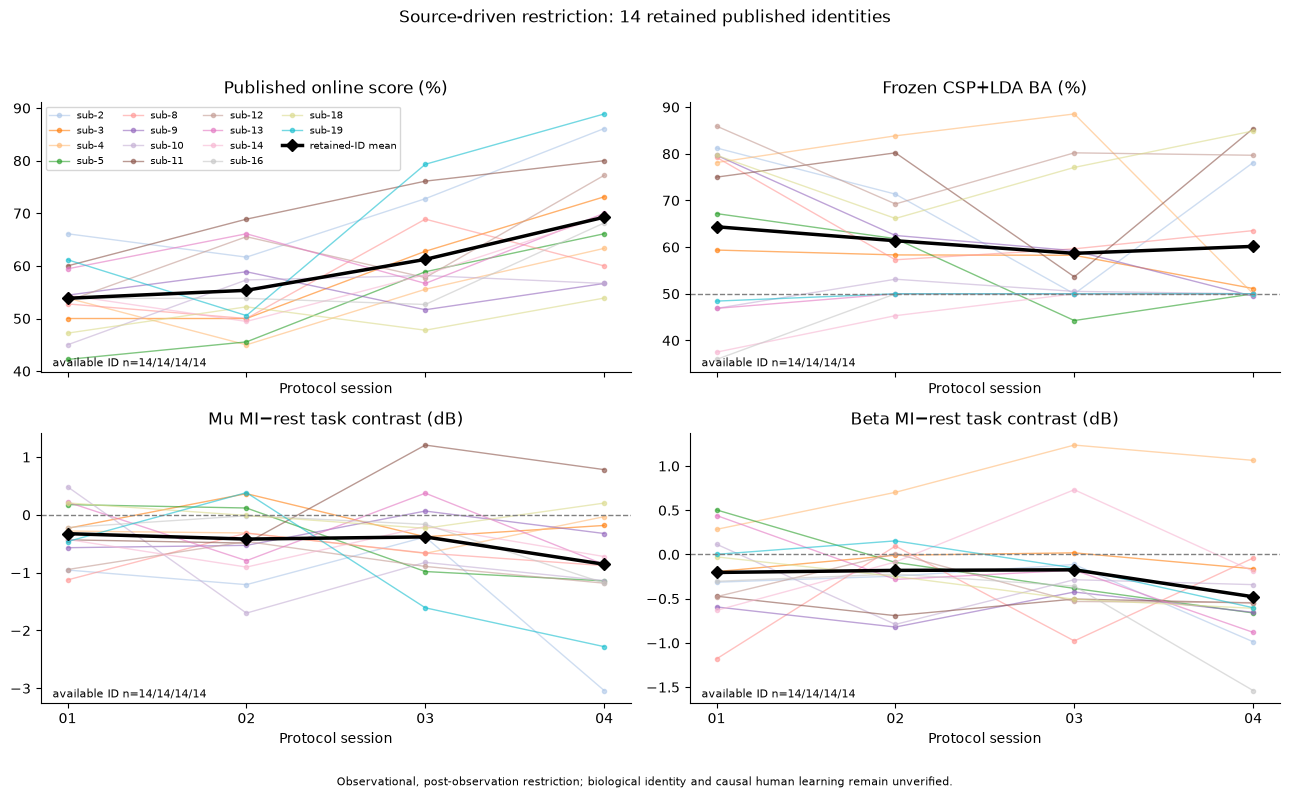

In [5]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {s: plt.get_cmap("tab20")(i % 20) for i, s in enumerate(SUBJECTS)}
X = np.arange(len(SESSIONS)) + 1
METRICS = [("mean_run_hit_percent", "Published online score (%)"),
           ("CSP_BA_percent", "Frozen CSP+LDA BA (%)"),
           ("mu_MI_minus_rest_dB", "Mu MI−rest task contrast (dB)"),
           ("beta_MI_minus_rest_dB", "Beta MI−rest task contrast (dB)")]
def matrix(frame, field, subjects):
    return frame.pivot(index="subject", columns="session", values=field).reindex(
        index=subjects, columns=SESSIONS).to_numpy(dtype=float)
def finite_mean(array):
    count = np.isfinite(array).sum(axis=0)
    return np.divide(np.nansum(array, axis=0), count,
                     out=np.full(array.shape[1], np.nan), where=count > 0), count
def close_figure(fig):
    figure_number = len(figure_exports) + 1
    stem = FIGURE_ROOT / f"native_figure_{figure_number:02d}"
    assert not any(stem.with_suffix(suffix).exists() for suffix in [".png", ".svg", ".pdf"])
    exports = []
    for suffix in [".png", ".svg", ".pdf"]:
        path = stem.with_suffix(suffix)
        fig.savefig(path, dpi=180, bbox_inches="tight")
        exports.append({"path": str(path.relative_to(ROOT)), "sha256": sha256(path),
                        "bytes": path.stat().st_size})
    figure_exports.append({"figure_number": figure_number, "artifacts": exports})
    display(fig)
    plt.close(fig)
FIGURE_ROOT = AUDIT / VALIDATION_RUN / "exports"
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
figure_exports = []
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for ax, (metric, label) in zip(axes.flat, METRICS):
    values = matrix(restricted, metric, RETAINED)
    for subject, series in zip(RETAINED, values):
        ax.plot(X, series, "o-", color=COLORS[subject], alpha=.6,
                linewidth=1, markersize=3, label=subject)
    mean, count = finite_mean(values)
    ax.plot(X, mean, "D-", color="black", lw=2.5, label="retained-ID mean")
    ax.set(title=label, xticks=X, xticklabels=SESSIONS, xlabel="Protocol session")
    ax.text(.02, .02, "available ID n=" + "/".join(map(str, count)), transform=ax.transAxes, fontsize=8)
axes[0, 0].legend(ncol=4, fontsize=7)
axes[0, 1].axhline(50, color="grey", ls="--", lw=1)
for ax in axes[1]: ax.axhline(0, color="grey", ls="--", lw=1)
fig.suptitle(f"Source-driven restriction: {len(RETAINED)} retained published identities")
fig.text(.5, .01, "Observational, post-observation restriction; biological identity and causal human learning remain unverified.", ha="center", fontsize=8)
fig.tight_layout(rect=[0, .04, 1, .95]); close_figure(fig)

Individual retained-ID trajectories above preserve heterogeneous outcomes.
Online behavior is an aggregate published score; BA reads the frozen
offline model. A decline in BA does not identify loss of human skill.

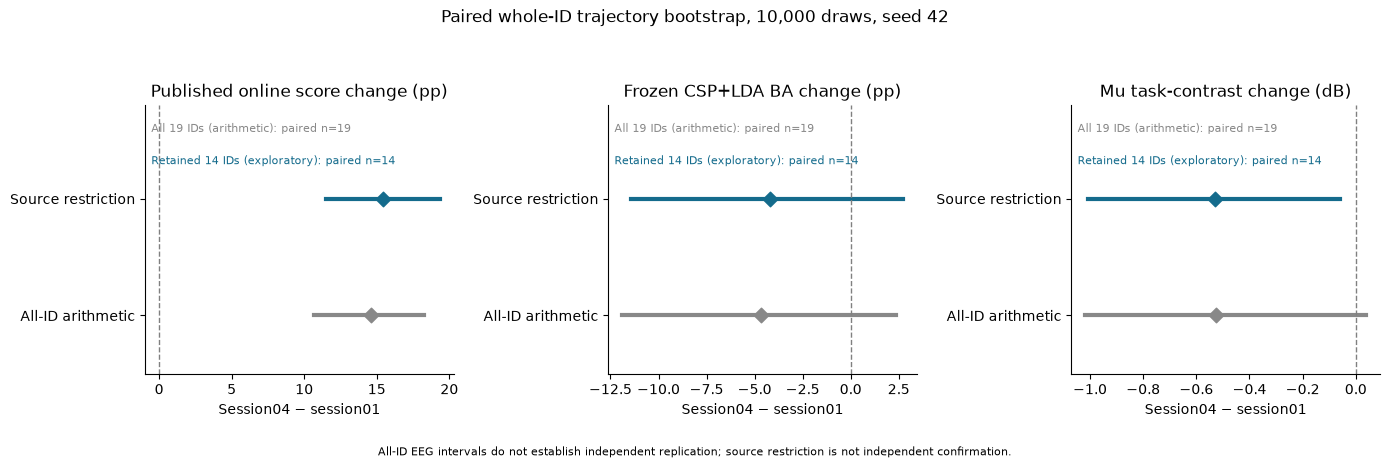

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
change_metrics = [("mean_run_hit_percent", "Published online score change (pp)"),
                  ("CSP_BA_percent", "Frozen CSP+LDA BA change (pp)"),
                  ("mu_MI_minus_rest_dB", "Mu task-contrast change (dB)")]
for ax, (metric, label) in zip(axes, change_metrics):
    for position, (frame, legend, color) in enumerate([
        (paired, f"All {len(SUBJECTS)} IDs (arithmetic)", "#888888"),
        (sensitive_paired, f"Retained {len(RETAINED)} IDs (exploratory)", "#146b8c")]):
        row = frame.loc[frame.metric == metric].iloc[0]
        ax.plot([row.subject_bootstrap_CI95_low, row.subject_bootstrap_CI95_high],
                [position, position], color=color, lw=3)
        ax.scatter(row.mean_change, position, color=color, s=55, marker="D")
        ax.text(.02, .9 - position*.12, f"{legend}: paired n={int(row.n_paired_subjects)}",
                transform=ax.transAxes, fontsize=8, color=color)
    ax.axvline(0, color="grey", ls="--", lw=1)
    ax.set(yticks=[0, 1], yticklabels=["All-ID arithmetic", "Source restriction"],
           ylim=(-.5, 1.8), title=label, xlabel="Session04 − session01")
fig.suptitle("Paired whole-ID trajectory bootstrap, 10,000 draws, seed 42")
fig.text(.5, .01, "All-ID EEG intervals do not establish independent replication; source restriction is not independent confirmation.", ha="center", fontsize=8)
fig.tight_layout(rect=[0, .06, 1, .92]); close_figure(fig)

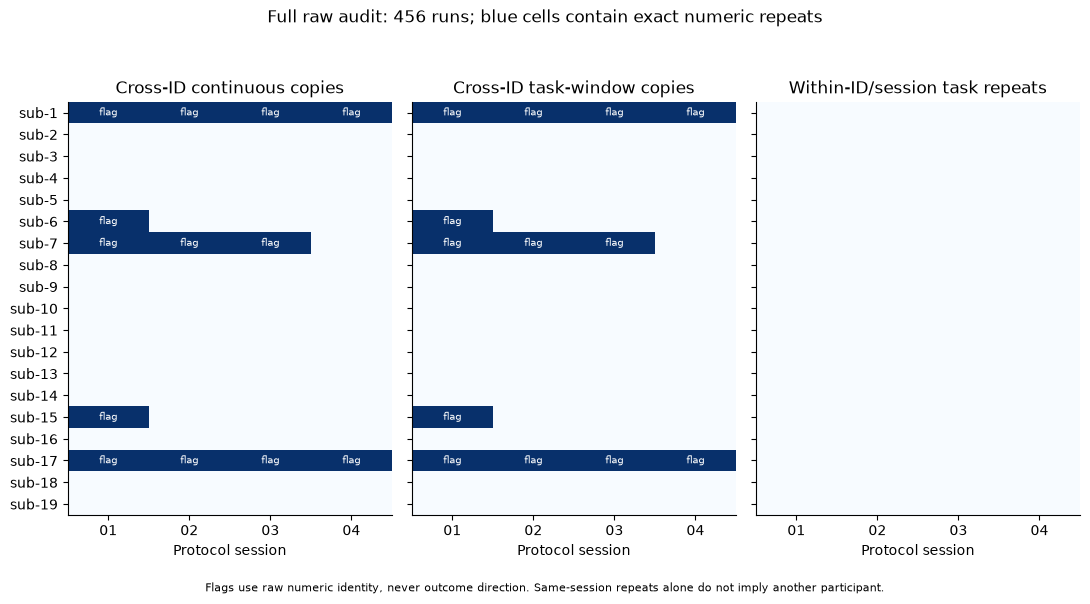

In [7]:
continuous = np.zeros((len(SUBJECTS), len(SESSIONS)))
task = np.zeros_like(continuous)
repeat = np.zeros_like(continuous)
for group in compact["continuous_duplicate_groups"]:
    if group["cross_subject"]:
        for member in group["members"]:
            subject, session, _ = member["identity"].split("/")
            continuous[SUBJECTS.index(subject), SESSIONS.index(session.removeprefix("ses-"))] = 1
for row in compact["cross_subject_task_window_affected_subject_sessions"]:
    task[SUBJECTS.index(row["subject"]), SESSIONS.index(row["session"])] = 1
for row in compact["same_subject_session_task_repeat_flags"]:
    repeat[SUBJECTS.index(row["subject"]), SESSIONS.index(row["session"])] = 1
fig, axes = plt.subplots(1, 3, figsize=(11, max(6, len(SUBJECTS)*.29)), sharey=True)
for ax, data, title in zip(axes, [continuous, task, repeat],
                          ["Cross-ID continuous copies", "Cross-ID task-window copies", "Within-ID/session task repeats"]):
    ax.imshow(data, aspect="auto", vmin=0, vmax=1, cmap="Blues")
    ax.set(xticks=np.arange(4), xticklabels=SESSIONS, yticks=np.arange(len(SUBJECTS)),
           yticklabels=SUBJECTS, xlabel="Protocol session", title=title)
    for i, j in zip(*np.where(data)): ax.text(j, i, "flag", ha="center", va="center", color="white", fontsize=7)
fig.suptitle(f"Full raw audit: {compact['summary']['continuous_runs']} runs; blue cells contain exact numeric repeats")
fig.text(.5, .01, "Flags use raw numeric identity, never outcome direction. Same-session repeats alone do not imply another participant.", ha="center", fontsize=8)
fig.tight_layout(rect=[0, .04, 1, .94]); close_figure(fig)

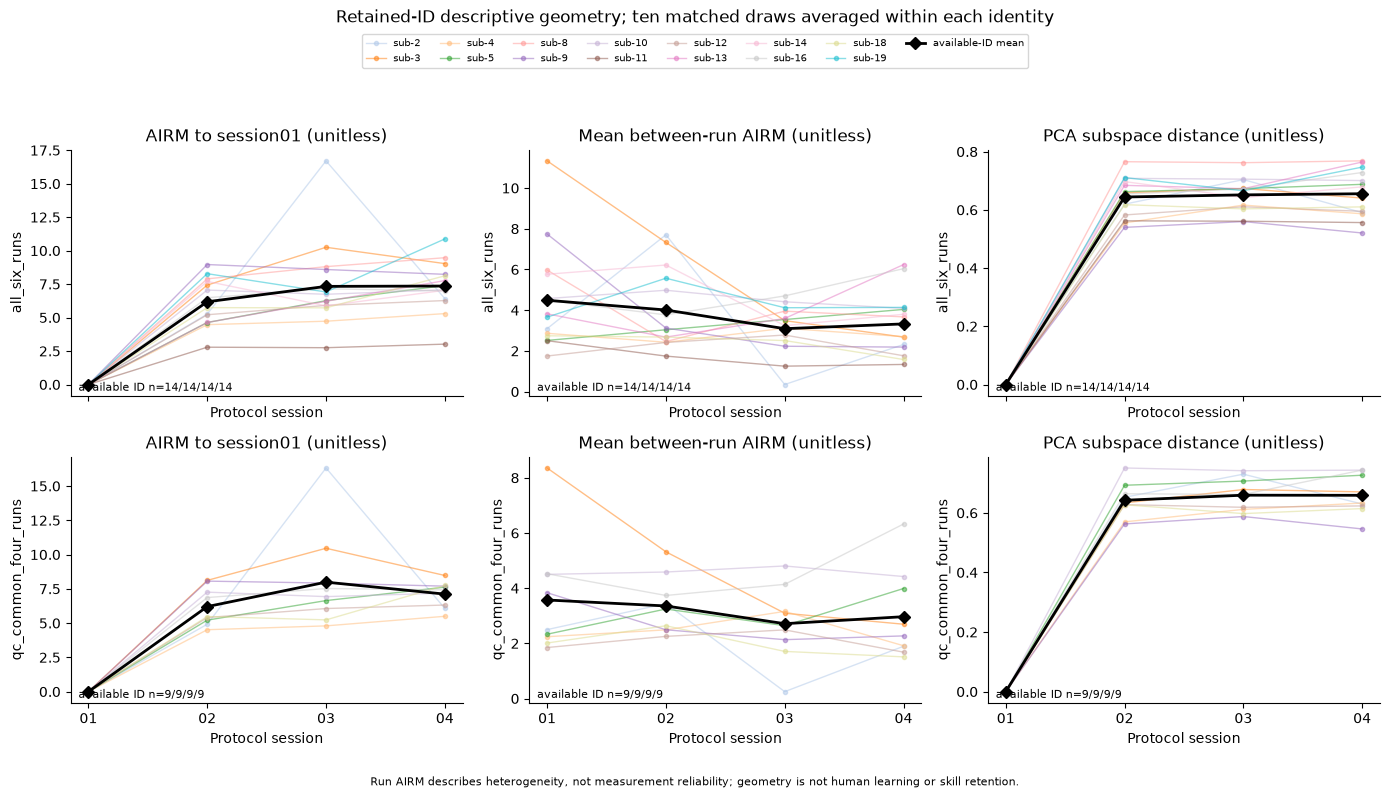

In [8]:
selected_geometry = geometry.loc[geometry.subject.isin(RETAINED)]
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True)
geometry_titles = ["AIRM to session01 (unitless)",
                   "Mean between-run AIRM (unitless)",
                   "PCA subspace distance (unitless)"]
for i, variant in enumerate(["all_six_runs", "qc_common_four_runs"]):
    data = selected_geometry.loc[selected_geometry.variant == variant]
    for ax, field, title in zip(axes[i],
            ["AIRM_to_session01", "within_session_run_AIRM_mean", "PCA_subspace_distance"],
            geometry_titles):
        values = matrix(data, field, RETAINED)
        for subject, series in zip(RETAINED, values):
            ax.plot(X, series, "o-", color=COLORS[subject], alpha=.5, lw=1, markersize=3, label=subject)
        mean, count = finite_mean(values)
        ax.plot(X, mean, "D-", color="black", lw=2, label="available-ID mean")
        ax.set(title=title, ylabel=variant, xticks=X, xticklabels=SESSIONS, xlabel="Protocol session")
        ax.text(.02, .02, "available ID n=" + "/".join(map(str, count)), transform=ax.transAxes, fontsize=8)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=8, fontsize=7, loc="upper center", bbox_to_anchor=(.5, .955))
fig.suptitle("Retained-ID descriptive geometry; ten matched draws averaged within each identity")
fig.text(.5, .01, "Run AIRM describes heterogeneity, not measurement reliability; geometry is not human learning or skill retention.", ha="center", fontsize=8)
fig.tight_layout(rect=[0, .04, 1, .89]); close_figure(fig)

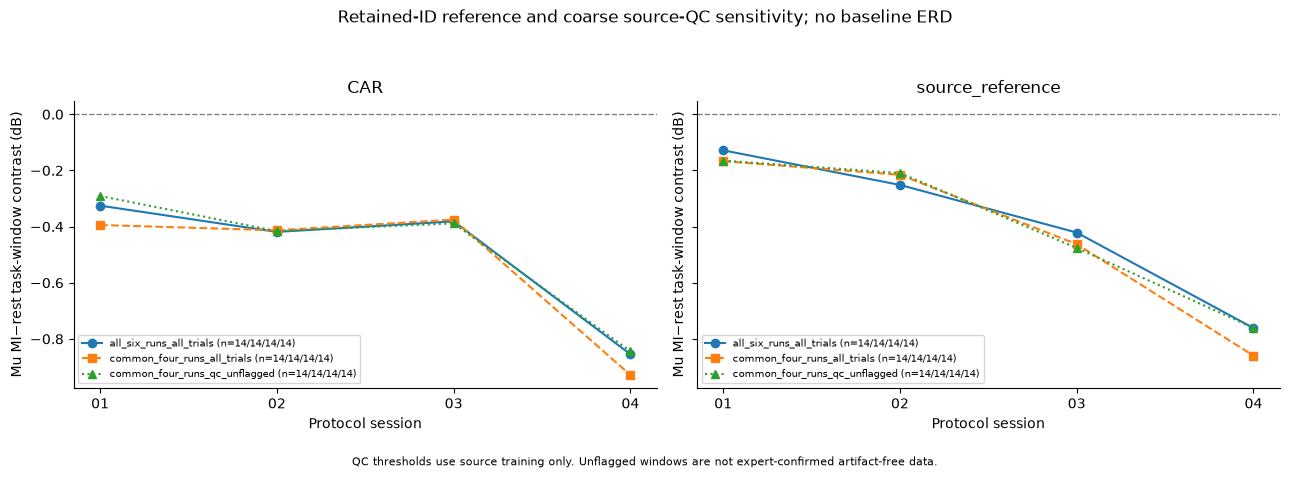

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.7), sharey=True)
for ax, reference in zip(axes, ["CAR", "source_reference"]):
    for variant, style in [("all_six_runs_all_trials", "o-"),
                           ("common_four_runs_all_trials", "s--"),
                           ("common_four_runs_qc_unflagged", "^:")]:
        data = spectral.loc[spectral.subject.isin(RETAINED) & (spectral.reference == reference)
                            & (spectral.variant == variant) & (spectral.band == "mu")]
        values = matrix(data, "MI_minus_rest_log_power_dB", RETAINED)
        mean, count = finite_mean(values)
        ax.plot(X, mean, style, label=variant + " (n=" + "/".join(map(str, count)) + ")")
    ax.axhline(0, color="grey", ls="--", lw=1)
    ax.set(title=reference, xticks=X, xticklabels=SESSIONS, xlabel="Protocol session",
           ylabel="Mu MI−rest task-window contrast (dB)")
    ax.legend(fontsize=7, loc="best")
fig.suptitle("Retained-ID reference and coarse source-QC sensitivity; no baseline ERD")
fig.text(.5, .01, "QC thresholds use source training only. Unflagged windows are not expert-confirmed artifact-free data.", ha="center", fontsize=8)
fig.tight_layout(rect=[0, .05, 1, .93]); close_figure(fig)

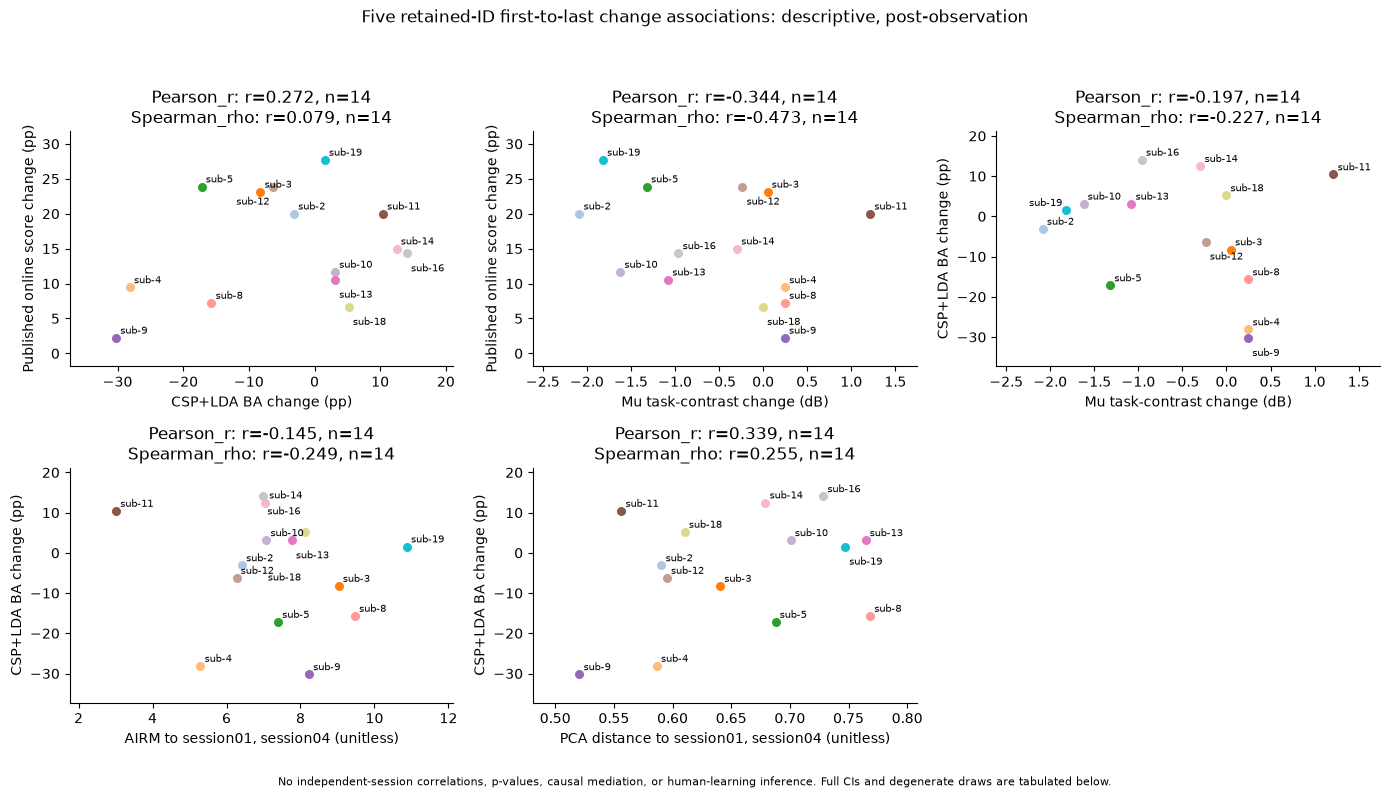

,association,x_metric,y_metric,x_units,y_units,estimator,n_requested_participants,n_complete_paired_participants,complete_subjects,unavailable_subjects,...,participant_bootstrap_CI95_low,participant_bootstrap_CI95_high,bootstrap_seed,bootstrap_repetitions_requested,bootstrap_repetitions_attempted,bootstrap_valid_draws,bootstrap_degenerate_draws,bootstrap_fewer_than_two_distinct_subject_draws,bootstrap_zero_variance_other_draws,CI_scope
0,BA_change_vs_behavior_change,CSP_BA_change_pp,behavior_change_pp,percentage points,percentage points,Pearson_r,14,14,"sub-2,sub-3,sub-4,sub-5,sub-8,sub-9,sub-10,sub...",NaN,...,-0.478108,0.668240,42,10000,10000,10000,0,0,0,whole paired participants; complete-variable p...
1,BA_change_vs_behavior_change,CSP_BA_change_pp,behavior_change_pp,percentage points,percentage points,Spearman_rho,14,14,"sub-2,sub-3,sub-4,sub-5,sub-8,sub-9,sub-10,sub...",NaN,...,-0.602788,0.638895,42,10000,10000,10000,0,0,0,whole paired participants; complete-variable p...
2,Mu_change_vs_behavior_change,mu_task_contrast_change_dB,behavior_change_pp,dB,percentage points,Pearson_r,14,14,"sub-2,sub-3,sub-4,sub-5,sub-8,sub-9,sub-10,sub...",NaN,...,-0.784124,0.165964,42,10000,10000,10000,0,0,0,whole paired participants; complete-variable p...
3,Mu_change_vs_behavior_change,mu_task_contrast_change_dB,behavior_change_pp,dB,percentage points,Spearman_rho,14,14,"sub-2,sub-3,sub-4,sub-5,sub-8,sub-9,sub-10,sub...",NaN,...,-0.793722,0.069699,42,10000,10000,10000,0,0,0,whole paired participants; complete-variable p...
4,Mu_change_vs_BA_change,mu_task_contrast_change_dB,CSP_BA_change_pp,dB,percentage points,Pearson_r,14,14,"sub-2,sub-3,sub-4,sub-5,sub-8,sub-9,sub-10,sub...",NaN,...,-0.689336,0.325519,42,10000,10000,10000,0,0,0,whole paired participants; complete-variable p...
5,Mu_change_vs_BA_change,mu_task_contrast_change_dB,CSP_BA_change_pp,dB,percentage points,Spearman_rho,14,14,"sub-2,sub-3,sub-4,sub-5,sub-8,sub-9,sub-10,sub...",NaN,...,-0.761811,0.394077,42,10000,10000,10000,0,0,0,whole paired participants; complete-variable p...
6,all_six_runs_AIRM_session04_vs_BA_change,all_six_AIRM_session04,CSP_BA_change_pp,AIRM distance,percentage points,Pearson_r,14,14,"sub-2,sub-3,sub-4,sub-5,sub-8,sub-9,sub-10,sub...",NaN,...,-0.598086,0.423786,42,10000,10000,10000,0,0,0,whole paired participants; complete-variable p...
7,all_six_runs_AIRM_session04_vs_BA_change,all_six_AIRM_session04,CSP_BA_change_pp,AIRM distance,percentage points,Spearman_rho,14,14,"sub-2,sub-3,sub-4,sub-5,sub-8,sub-9,sub-10,sub...",NaN,...,-0.709162,0.369134,42,10000,10000,10000,0,0,0,whole paired participants; complete-variable p...
8,all_six_runs_PCA_session04_vs_BA_change,all_six_PCA_subspace_session04,CSP_BA_change_pp,normalized projector distance,percentage points,Pearson_r,14,14,"sub-2,sub-3,sub-4,sub-5,sub-8,sub-9,sub-10,sub...",NaN,...,-0.335901,0.770958,42,10000,10000,10000,0,0,0,whole paired participants; complete-variable p...
9,all_six_runs_PCA_session04_vs_BA_change,all_six_PCA_subspace_session04,CSP_BA_change_pp,normalized projector distance,percentage points,Spearman_rho,14,14,"sub-2,sub-3,sub-4,sub-5,sub-8,sub-9,sub-10,sub...",NaN,...,-0.400045,0.769240,42,10000,10000,10000,0,0,0,whole paired participants; complete-variable p...


In [10]:
sys.path.insert(0, str(ROOT / "scripts"))
from analyze_netbci_cohort_associations import PAIRS, participant_values
values = pd.DataFrame(participant_values(restricted.astype(object).where(pd.notna(restricted), None).to_dict("records"),
                      selected_geometry.astype(object).where(pd.notna(selected_geometry), None).to_dict("records"),
                      subjects=RETAINED))
axis_labels = {"CSP_BA_change_pp": "CSP+LDA BA change (pp)",
               "behavior_change_pp": "Published online score change (pp)",
               "mu_task_contrast_change_dB": "Mu task-contrast change (dB)",
               "all_six_AIRM_session04": "AIRM to session01, session04 (unitless)",
               "all_six_PCA_subspace_session04": "PCA distance to session01, session04 (unitless)"}
def label_scatter(ax, points):
    ax.margins(x=.16, y=.16)
    ax.figure.canvas.draw()
    renderer = ax.figure.canvas.get_renderer()
    boxes = []
    offsets = [(3, 3), (3, -13), (-3, 3), (-3, -13),
               (3, 14), (3, -24), (-3, 14), (-3, -24),
               (3, 25), (3, -35), (-3, 25), (-3, -35)]
    for subject, x, y in points:
        annotation = ax.annotate(subject, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
        for dx, dy in offsets:
            annotation.set_position((dx, dy))
            annotation.set_ha("left" if dx > 0 else "right")
            box = annotation.get_window_extent(renderer).expanded(1.07, 1.15)
            if (not any(box.overlaps(other) for other in boxes)
                    and ax.bbox.contains(box.x0, box.y0) and ax.bbox.contains(box.x1, box.y1)):
                break
        boxes.append(box)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (pair, xfield, yfield) in zip(axes.flat, PAIRS):
    points = []
    for row in values.to_dict("records"):
        if pd.notna(row[xfield]) and pd.notna(row[yfield]):
            ax.scatter(row[xfield], row[yfield], color=COLORS[row["subject"]], s=30)
            points.append((row["subject"], row[xfield], row[yfield]))
    label_scatter(ax, points)
    estimate_rows = estimates.loc[estimates.association == pair]
    labels = []
    for row in estimate_rows.itertuples():
        labels.append(f"{row.estimator}: r={row.estimate:.3f}, n={int(row.n_complete_paired_participants)}")
    ax.set(title="\n".join(labels), xlabel=axis_labels[xfield], ylabel=axis_labels[yfield])
axes.flat[-1].axis("off")
fig.suptitle("Five retained-ID first-to-last change associations: descriptive, post-observation")
fig.text(.5, .01, "No independent-session correlations, p-values, causal mediation, or human-learning inference. Full CIs and degenerate draws are tabulated below.", ha="center", fontsize=8)
fig.tight_layout(rect=[0, .04, 1, .94]); close_figure(fig)
display(estimates)

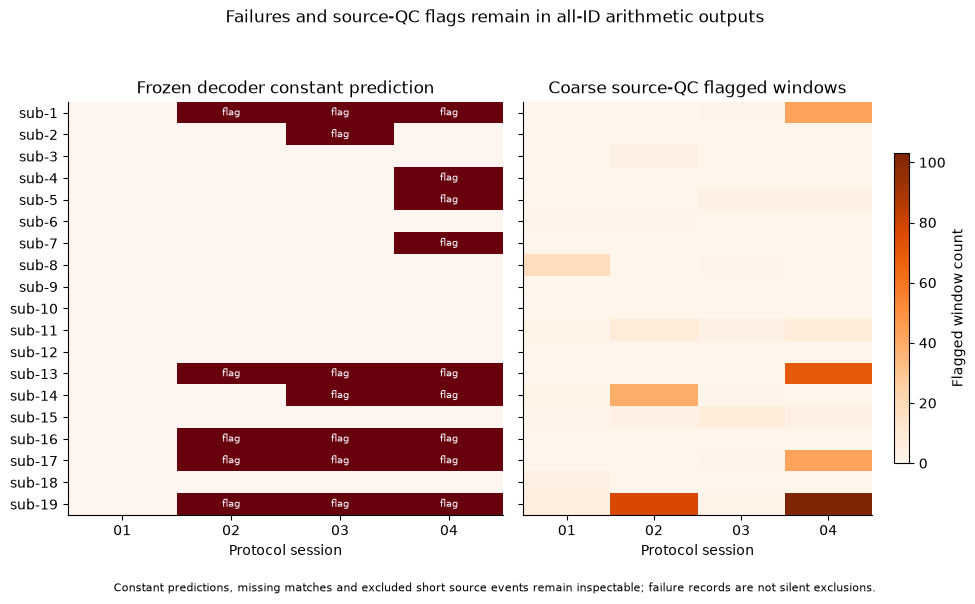

In [11]:
availability = np.array([[int(str(row).lower() == "true") for row in
                         joined.loc[joined.subject == s].set_index("session").reindex(SESSIONS).CSP_constant_prediction]
                         for s in SUBJECTS])
qc = matrix(joined, "n_qc_flagged", SUBJECTS)
fig, axes = plt.subplots(1, 2, figsize=(10, max(6, len(SUBJECTS)*.29)), sharey=True)
image = axes[0].imshow(availability, aspect="auto", cmap="Reds", vmin=0, vmax=1)
axes[0].set_title("Frozen decoder constant prediction")
image = axes[1].imshow(qc, aspect="auto", cmap="Oranges", vmin=0)
axes[1].set_title("Coarse source-QC flagged windows")
fig.colorbar(image, ax=axes[1], shrink=.75, label="Flagged window count")
for ax in axes:
    ax.set(xticks=np.arange(4), xticklabels=SESSIONS, yticks=np.arange(len(SUBJECTS)),
           yticklabels=SUBJECTS, xlabel="Protocol session")
for i, j in zip(*np.where(availability)): axes[0].text(j, i, "flag", color="white", ha="center", va="center", fontsize=7)
fig.suptitle("Failures and source-QC flags remain in all-ID arithmetic outputs")
fig.text(.5, .01, "Constant predictions, missing matches and excluded short source events remain inspectable; failure records are not silent exclusions.", ha="center", fontsize=8)
fig.tight_layout(rect=[0, .04, 1, .94]); close_figure(fig)

## Reproducibility and remaining evidence gaps

The tables below record source/output hashes and actual notebook runtime.
The full raw numeric ledger is preserved locally; R2 synchronization
and full GET confirmation require separate per-file receipts;
the compact summary records its SHA-256. A storage ETag or HEAD metadata
match is not proof of downloaded content identity; R2 receipts distinguish
full GET checks from metadata checks.

Exact copy exclusion cannot identify the correctly assigned original EEG,
remove unknown acquisition confounds, or establish external replication.
Biological measurement reliability, unassisted same-mapping probes,
delayed retention, randomized intervention and new algorithms remain pending.
Public training resources are a separate audit/ingestion scope, never silently
appended to this longitudinal cohort or online behavior sample size.

In [12]:
display(pd.DataFrame(source_rows))
versions = {package: importlib.metadata.version(package) for package in
            ["numpy", "pandas", "scipy", "matplotlib", "mne", "scikit-learn", "nbformat", "nbclient"]}
versions["python"] = platform.python_version()
print(json.dumps(versions, indent=2))
assert len(figure_exports) == 7
figure_index = FIGURE_ROOT.parent / "native_figure_export_index.json"
assert not figure_index.exists(), "Preserve previous figure export index."
figure_index.write_text(json.dumps(figure_exports, indent=2) + "\n")

,artifact,SHA256
0,research_logs/netbci_cohort_all19_20261010/sum...,f6c2a97d0a7e53cdb31896fc9ee0edf6c01df47c68ce6c...
1,research_logs/netbci_cohort_all19_20261010/sum...,97cea3574569f0c172b939e383a4f857a78849ce4db824...
2,research_logs/netbci_cohort_all19_20261010/sum...,3bb85570178de6bd284033ab004717b2b10a48df2eaf53...
3,research_logs/netbci_cohort_all19_20261010/sum...,cbbd8e9a57feea7222976cc735ebb9fc148ac576fddd3d...
4,research_logs/netbci_cohort_all19_20261010/sum...,f3a93ec0cd770ea2c6f83dfb549bcb3abc33d2f473e15e...
5,research_logs/netbci_cohort_all19_20261010/sum...,a23ca1b0525314ef4fe289afb51078f5e8afef116c1a06...
6,research_logs/netbci_cohort_all19_20261010/sum...,58a31f04a08996e970ba72b1765c3ecabe31cae0ee7b1f...
7,research_logs/netbci_cohort_all19_20261010/sum...,35754d13262f023a92c85ad4af3be3c5cd3420ce41e007...
8,research_logs/netbci_cohort_all19_20261010/sum...,3297826f9a6e85697930d909869a8b4f12194fa1f9b651...
9,research_logs/netbci_cohort_all19_20261010/sum...,cab31c021aa4c46650c3d41a7da6b0674c44cbbaf9a8cf...


{
  "numpy": "2.2.6",
  "pandas": "3.0.6",
  "scipy": "1.15.3",
  "matplotlib": "3.11.2",
  "mne": "1.10.2",
  "scikit-learn": "1.7.2",
  "nbformat": "5.10.4",
  "nbclient": "0.10.2",
  "python": "3.11.16"
}


5515